In [2]:
import os
import pandas as pd
import numpy as np

In [3]:
import urllib.request


# Initialize path and Load in the Ames Housing Data
path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/iris_data.csv"
data= "iris_data.db"

if not os.path.exists(data) or os.path.getsize(data) == 0:
    urllib.request.urlretrieve(path, data)

data = pd.read_csv(data)

# Question 1
Load the data from the file using the techniques learned today. Examine it.

Determine the following:

The number of data points (rows). (Hint: check out the dataframe .shape attribute.)

The column names. (Hint: check out the dataframe .columns attribute.)

The data types for each column. (Hint: check out the dataframe .dtypes attribute.)

In [4]:
print("Data shape:", data.shape)
print("Column names:", data.columns.to_list())
print("Data types:", data.dtypes)

Data shape: (150, 5)
Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
Data types: sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


# Question 2
Examine the species names and note that they all begin with 'Iris-'. Remove this portion of the name so the species name is shorter.

Hint: there are multiple ways to do this, but you could use either the string processing methods or the apply method.

In [5]:
data["species"] = data.species.str.replace("Iris", "")
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Question 3
Determine the following:

The number of each species present. (Hint: check out the series .value_counts method.)

The mean, median, and quantiles and ranges (max-min) for each petal and sepal measurement.

Hint: for the last question, the .describe method does have median, but it's not called median. It's the 50% quantile. .describe does not have range though, and in order to get the range, you will need to create a new entry in the .describe table, which is max - min.

In [8]:
data.species.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [13]:
stats_df = data.describe()
stats_df = data.describe()
stats_df.loc["range"] = stats_df.loc["max"] - stats_df.loc["min"]

out_field = ["mean", "std", "25%", "50%", "75%", "range"]
stats_df = stats_df.loc[out_field]
stats_df = stats_df.rename({'50': 'median'}, inplace=True)
stats_df

# Question 4
Calculate the following for each species in a separate dataframe:

The mean of each measurement (sepal_length, sepal_width, petal_length, and petal_width).

The median of each of these measurements.
Hint: you may want to use Pandas groupby method to group by species before calculating the statistic.

If you finish both of these, try calculating both statistics (mean and median) in a single table (i.e. with a single groupby call). See the section of the Pandas documentation on applying multiple functions at once for a hint.

In [15]:
data.groupby("species").mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [16]:
data.groupby("species").median()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.0,3.4,1.50,0.2
versicolor,5.9,2.8,4.35,1.3
virginica,6.5,3.0,5.55,2.0


In [19]:
# applying multiple functions at once - 2 methods
data.groupby("species").agg(["mean", "median"])
data.groupby("species").agg([np.mean, np.median])

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

In [20]:
# If certain fields need to be aggregated differently, we can do:
from pprint import pprint

agg_dict = {field: ["mean", "median"] for field in data.columns if field != "species"}
agg_dict["species"] = "max"
pprint(agg_dict)

data.groupby("species").agg(agg_dict)

{'petal_length': ['mean', 'median'],
 'petal_width': ['mean', 'median'],
 'sepal_length': ['mean', 'median'],
 'sepal_width': ['mean', 'median'],
 'species': 'max'}


sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width            species  
                  mean median         max  
species                                    
setosa           0.244    0.2      setosa  
versicolor       1.326    1.3  versicolor  
virginica        2.026    2.0   virginica

# Question 5
Make a scatter plot of sepal_length vs sepal_width using Matplotlib. Label the axes and give the plot a title.

In [24]:
import matplotlib.pyplot as plt
%matplotlib inline

[Text(0.5, 0, 'sepal length(cm)'),
 Text(0, 0.5, 'sepal width(cm)'),
 Text(0.5, 1.0, 'Sepal length vs Sepal width')]

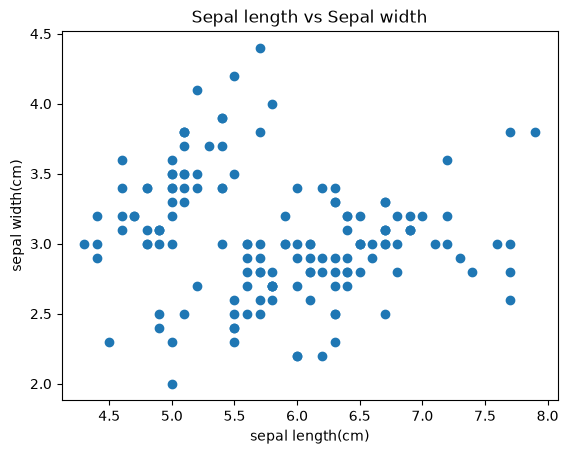

In [25]:
ax = plt.axes()

ax.scatter(data.sepal_length, data.sepal_width)

ax.set(xlabel="sepal length(cm)",
       ylabel="sepal width(cm)",
       title="Sepal length vs Sepal width")



# Question 6
Make a histogram of any one of the four features. Label axes and title it as appropriate.

[Text(0.5, 0, 'sepal length(cm)'),
 Text(0, 0.5, 'frequency'),
 Text(0.5, 1.0, 'Sepal length histogram')]

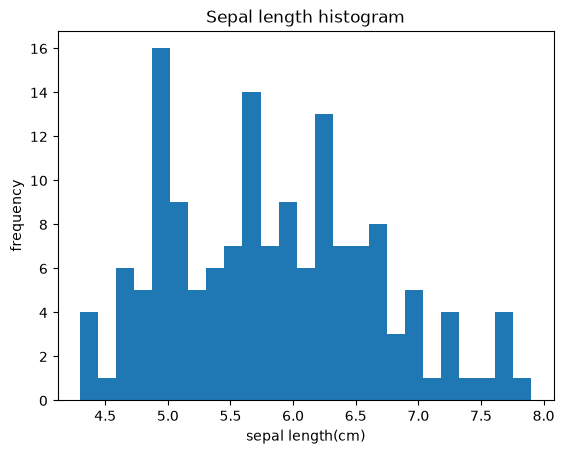

In [26]:
ax = plt.axes()
ax.hist(data.sepal_length, bins=25)

ax.set(xlabel="sepal length(cm)",
       ylabel="frequency",
       title="Sepal length histogram")

[Text(0.5, 0, 'Petal Length (cm)'),
 Text(0, 0.5, 'Frequency'),
 Text(0.5, 1.0, 'Distribution of Petal Lengths')]

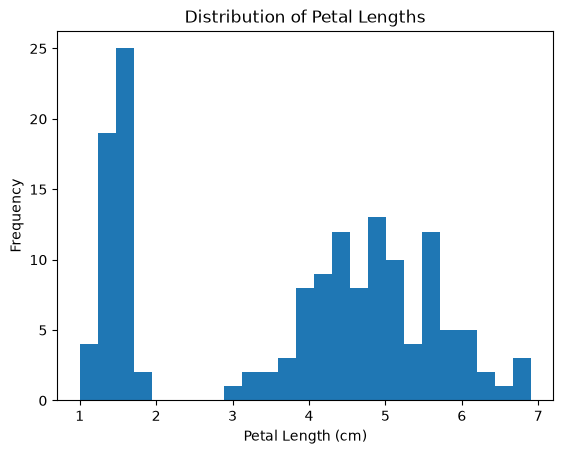

In [27]:
# Alternatively using Pandas plotting functionality
ax = data.petal_length.plot.hist(bins=25)

ax.set(xlabel='Petal Length (cm)', 
       ylabel='Frequency',
       title='Distribution of Petal Lengths')

Text(0.5, 0, 'Size(cm)')

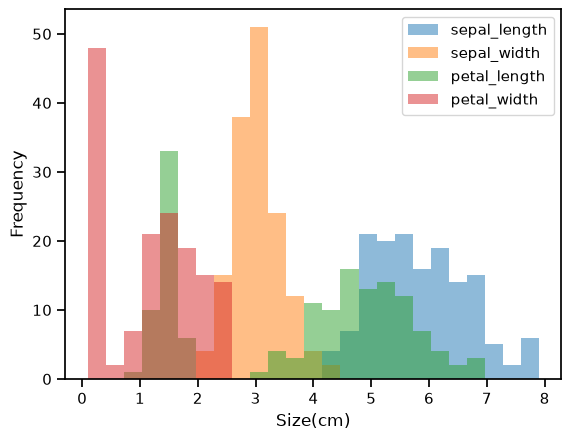

In [28]:
import seaborn as sns

sns.set_context("notebook")

ax = data.plot.hist(bins=25, alpha=0.5)
ax.set_xlabel('Size(cm)')

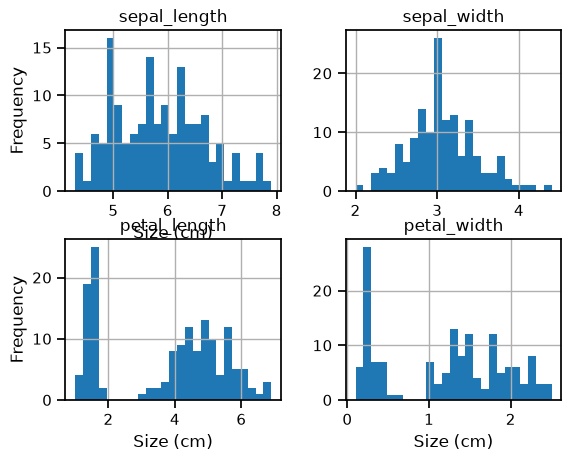

In [30]:
# To create four separate plots, use Pandas `.hist` method
axList = data.hist(bins=25)

# Add some x- and y- labels to first column and last row
for ax in axList.flatten():
    if ax.get_subplotspec().is_last_row():
        ax.set_xlabel('Size (cm)')

    if ax.get_subplotspec().is_first_col():
        ax.set_ylabel('Frequency')
        ax.set_xlabel('Size (cm)')
        
    if ax.get_subplotspec().is_first_col():
        ax.set_ylabel('Frequency')

# Question 8
Using Pandas, make a boxplot of each petal and sepal measurement

array([[<Axes: title={'center': 'petal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'petal_width'}, xlabel='[species]'>],
       [<Axes: title={'center': 'sepal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'sepal_width'}, xlabel='[species]'>]],
      dtype=object)

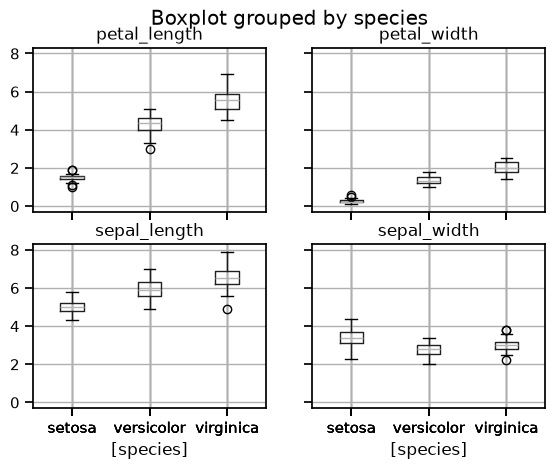

In [31]:
data.boxplot(by='species')


# Question 9
Now make a single boxplot where the features are separated in the x-axis and species are colored with different hues.

Hint: you may want to check the documentation for Seaborn boxplots.

Also note that Seaborn is very picky about data format--for this plot to work, the input dataframe will need to be manipulated so that each row contains a single data point (a species, a measurement type, and the measurement value). Check out Pandas stack method as a starting place.

In [32]:
plot_data = (data
             .set_index('species')
             .stack()
             .to_frame('size')
             .reset_index()
             .rename(columns={0: 'size', 'level_1': 'measurement'}))

plot_data.head()

,species,measurement,size
0,setosa,sepal_length,5.1
1,setosa,sepal_width,3.5
2,setosa,petal_length,1.4
3,setosa,petal_width,0.2
4,setosa,sepal_length,4.9


# Question 10
Make a pairplot with Seaborn to examine the correlation between each of the measurements.

Hint: this plot may look complicated, but it is actually only a single line of code. This is the power of Seaborn and dataframe-aware plotting! See the lecture notes for reference.

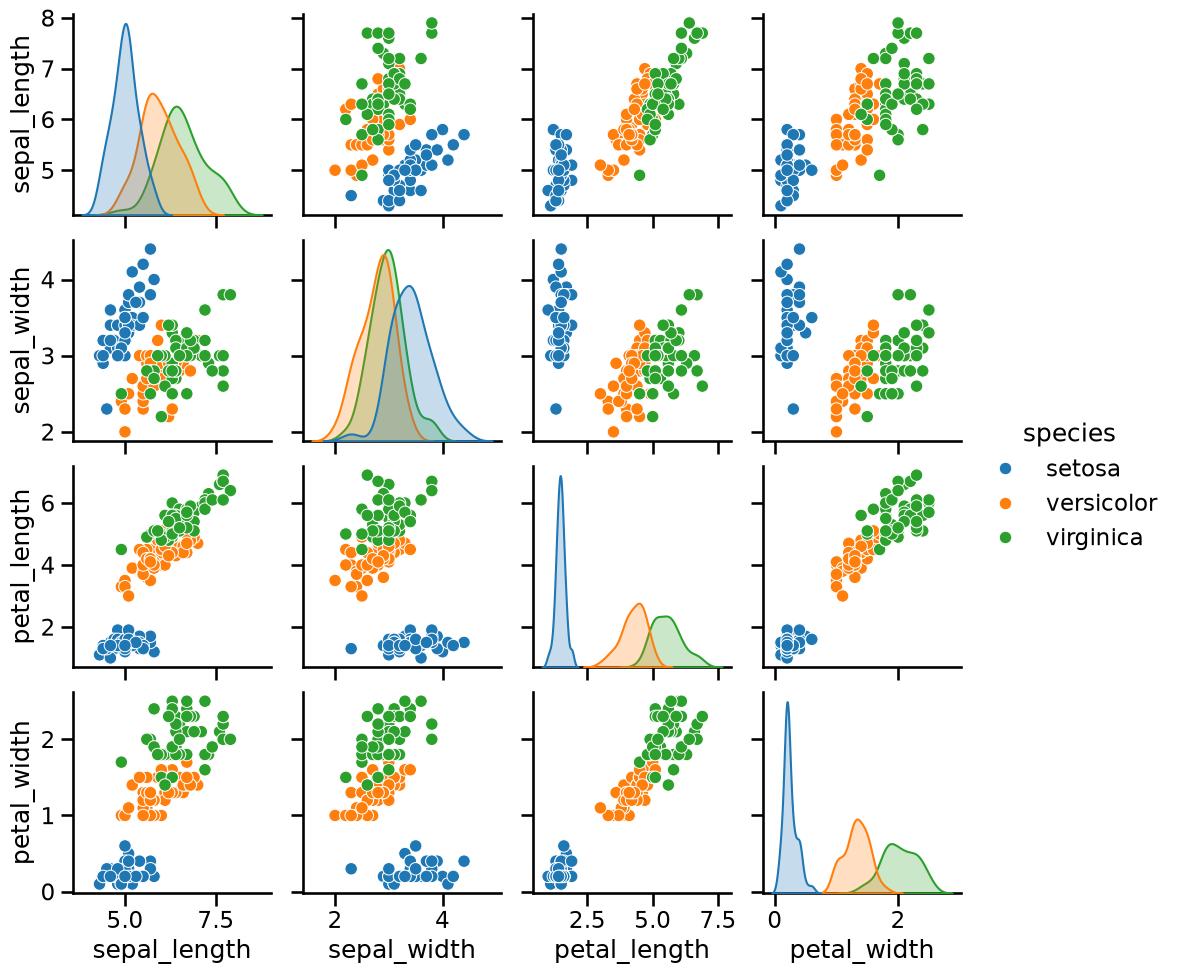

In [33]:
sns.set_context("talk")
sns.pairplot(data, hue='species')